# Classificação de renda anual — APS2
**Integrantes:** Enzo Santoro e Victor Dolnikoff  
**Disciplina:** Machine Learning  
**Data da entrega:** 16/10/2026 · **Prazo da rubrica:** 26/10  
**Site do projeto (APS1 e APS2):** https://viviraia.github.io/ml-adult-income/  
**Problema:** identificar renda anual `>50K` (classe positiva = 1) no Adult Income Census.

Este notebook dá continuidade à APS1, com os mesmos 31.947 registros, 11 preditores e split estratificado 80/20, semente 42. Contém execução completa, resultados e interpretações. Para reproduzir no Colab: **Ambiente de execução → Executar tudo**. Os dados da versão Kaggle utilizada estão incorporados em uma célula comprimida, sem depender de autenticação ou downloads futuros. A primeira execução instala SHAP apenas se necessário; a busca e as curvas podem levar vários minutos em CPU.

**Roteiro:** protocolo e continuidade → três modelos → ajuste → mudança de pipeline → curvas → teste → explicabilidade → discussão e referências. Nenhuma submissão ou publicação externa é feita por este notebook.


## 1. Protocolo e continuidade com a APS1
A APS1 usa três numéricas (`age`, `fnlwgt`, `education.num`) e oito categóricas. Reproduzimos seu pipeline executado: mediana + StandardScaler nas numéricas; moda + one-hot denso com categorias desconhecidas ignoradas nas categóricas. O PCA da APS1 era uma variante diagnóstica sem compressão (3 → 3 componentes); não é o pipeline principal reutilizado aqui.

**Discrepância auditada:** o texto da APS1 diz que `?` e `occupation` foram convertidos em ausentes, mas a célula de carga e suas saídas mantêm esses valores como categorias. A referência inicial nesta APS2 reproduz o **código efetivamente executado**. A mudança formal será inserir a limpeza desses sentinelas antes da imputação. Assim, a comparação mede uma alteração identificável, sem trocar o dataset ou misturar várias intervenções.

**Métrica de seleção: F1 da classe >50K**, média de três dobras estratificadas fixas. F1 combina precisão e recall e penaliza ignorar a classe minoritária; não assume que o custo dos erros é conhecido. Usamos limiar padrão 0,5 em todos os modelos e não o ajustamos no teste. Accuracy e ROC-AUC serão complementares na avaliação final. Não balanceamos artificialmente o teste.

Todos os estimadores recebem os dados crus em um Pipeline: imputação, escala e categorias são ajustadas dentro de cada dobra. A seleção em CV é otimista após várias tentativas, portanto a estimativa final vem do teste reservado; não afirmamos significância estatística das pequenas diferenças de CV.


In [1]:
import importlib.util, subprocess, sys
for pacote in ["shap"]:
    if importlib.util.find_spec(pacote) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pacote])

import io, base64, zlib, hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, shap
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold,
    GridSearchCV, cross_val_score, cross_validate, learning_curve)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
RANDOM_STATE = 42
N_JOBS = 2  # evita multiplicar processos e exceder RAM no Colab
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_colwidth", 180)
print({"Python":platform.python_version(), "numpy":np.__version__, "pandas":pd.__version__,
       "sklearn":sklearn.__version__, "shap":shap.__version__})


{'Python': '3.13.4', 'numpy': '2.5.4', 'pandas': '3.1.0', 'sklearn': '1.9.1', 'shap': '0.54.1'}


### 1.1 Dados e rastreabilidade
Snapshot do arquivo `adult income1.csv`, obtido do pacote Kaggle `anaghakp/adult-income-census`, a mesma fonte da APS1. O hash SHA-256 confere os bytes; a seleção e a ordem das colunas são explícitas. Não substituímos a base reduzida pela versão UCI com 14 atributos. O bloco longo abaixo contém apenas os dados comprimidos.


In [2]:
# @title Dados incorporados: Adult Income Census (clique para expandir)
DADOS_B64 = '...'
SHA256_ESPERADO = 'b8d9cbbeb804b6ad4fad2b021933e4d0dd90cb9c7c579f1cf8cff31ae770501c'
conteudo = zlib.decompress(base64.b64decode(DADOS_B64))
assert hashlib.sha256(conteudo).hexdigest() == SHA256_ESPERADO
df = pd.read_csv(io.BytesIO(conteudo), skipinitialspace=True)
df.columns = df.columns.str.strip().str.lower()
ESQUEMA = ["age", "workclass", "fnlwgt", "education", "education.num", "marital.status",
           "occupation", "relationship", "race", "sex", "native.country", "income"]
df = df[ESQUEMA].copy()
df["income"] = df["income"].str.replace(".", "", regex=False).str.strip()
assert set(df.income.unique()) == {"<=50K", ">50K"}
assert df.shape == (31947, 12)
X = df.drop(columns="income")
# Estratificar pelas strings reproduz exatamente a partição da APS1.
X_train, X_test, ys_train, ys_test = train_test_split(
    X, df.income, test_size=.2, stratify=df.income, random_state=RANDOM_STATE)
y_train = ys_train.eq(">50K").astype(int)
y_test = ys_test.eq(">50K").astype(int)
assert X_train.index.intersection(X_test.index).empty
print("SHA-256:", SHA256_ESPERADO)
display(pd.DataFrame({"n":[len(X_train),len(X_test)],
    "fração >50K":[y_train.mean(),y_test.mean()]},index=["treino","teste"]))
display(pd.DataFrame({"? no treino":X_train.eq("?").sum(),
                     "sentinela occupation":X_train.eq("occupation").sum()}))
print("Duplicatas integrais preservadas:", df.duplicated().sum())


SHA-256: b8d9cbbeb804b6ad4fad2b021933e4d0dd90cb9c7c579f1cf8cff31ae770501c


,n,fração >50K
treino,25557,0.240482
teste,6390,0.240532


,? no treino,sentinela occupation
age,0,0
workclass,1425,0
fnlwgt,0,0
education,0,0
education.num,0,0
marital.status,0,0
occupation,1432,1188
relationship,0,0
race,0,0
sex,0,0


Duplicatas integrais preservadas: 65


### 1.2 Construção do pipeline
A imputação por moda na referência não afeta `?`, que é uma string; a variante corrige isso. Não removemos outliers plausíveis nem linhas: preservamos a identidade do split da APS1. `fnlwgt` permanece inicialmente como preditor, sem tratar o objetivo como estimativa populacional ponderada. As medidas são por registro. Duplicatas entre partições podem tornar a avaliação otimista; quantificamos essa sobreposição como diagnóstico, sem alterar o teste após sua escolha.


In [3]:
NUM = ["age", "fnlwgt", "education.num"]
CAT = [c for c in X_train.columns if c not in NUM]

def construir_preprocessador(num=NUM, cat=CAT):
    return ColumnTransformer([
        ("num", Pipeline([("imputer",SimpleImputer(strategy="median")),
                          ("scaler",StandardScaler())]), list(num)),
        ("cat", Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                          ("onehot",OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), list(cat))
    ], remainder="drop")

class LimparSentinelas(TransformerMixin, BaseEstimator):
    """Transformação determinística, sem estatísticas do treino ou do teste."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        saida = X.copy()
        for c in saida.select_dtypes(exclude=np.number):
            saida[c] = saida[c].str.strip().replace({"?":np.nan, "":np.nan})
        if "occupation" in saida:
            saida["occupation"] = saida["occupation"].replace("occupation", np.nan)
        return saida

def montar(modelo, limpar=False, num=NUM, cat=CAT):
    return Pipeline([("limpeza", LimparSentinelas() if limpar else "passthrough"),
                     ("preprocessor", construir_preprocessador(num,cat)), ("model", modelo)])

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
DOBRAS = list(cv.split(X_train, y_train))  # exatamente as mesmas em todas as comparações
SCORING = "f1"
h_treino = set(pd.util.hash_pandas_object(X_train, index=False))
h_teste = pd.util.hash_pandas_object(X_test, index=False)
print("Registros do teste com preditores idênticos a algum treino:", h_teste.isin(h_treino).sum())


Registros do teste com preditores idênticos a algum treino: 22


## 2. Seleção e implementação dos três modelos
**Dummy (most_frequent):** referência majoritária, que permite demonstrar por que acurácia isolada é inadequada. Por isso reportamos também sua acurácia na comparação inicial, ao lado do F1. **Regressão logística L2:** modelo linear regularizado, interpretável em log-odds; C controla a penalização e class_weight testa o equilíbrio de erros. **Random Forest:** ensemble por bagging que aprende interações e não linearidades; profundidade e tamanho mínimo das folhas limitam o sobreajuste. Usamos 100 árvores fixas para tornar a busca viável em CPU.

Os três modelos primeiro são comparados sem ajuste. Depois ajustamos separadamente os dois modelos reais por GridSearchCV, com a mesma métrica e as mesmas dobras.


In [4]:
iniciais = {
    "Dummy": montar(DummyClassifier(strategy="most_frequent")),
    "Logística L2": montar(LogisticRegression(C=1, solver="lbfgs", max_iter=1500, random_state=42)),
    "Random Forest": montar(RandomForestClassifier(n_estimators=100, max_depth=16,
                     min_samples_leaf=3, n_jobs=1, random_state=42))}
linhas = []
for nome, modelo in iniciais.items():
    # F1 é a métrica de seleção; a acurácia só contextualiza o Dummy.
    res = cross_validate(modelo, X_train, y_train, cv=DOBRAS, scoring={"f1":SCORING, "accuracy":"accuracy"},
                         n_jobs=N_JOBS, error_score="raise")
    scores = res["test_f1"]
    linhas.append({"modelo":nome,"F1 médio":scores.mean(),"desvio entre dobras":scores.std(),
                   **{f"dobra {i+1}":v for i,v in enumerate(scores)},
                   "Accuracy média":res["test_accuracy"].mean()})
comparacao_inicial = pd.DataFrame(linhas).set_index("modelo")
display(comparacao_inicial.round(4))
acc_dummy = comparacao_inicial.loc["Dummy","Accuracy média"]
display(Markdown(f"O Dummy prevê apenas <=50K: obtém **accuracy de {acc_dummy:.1%}**, igual à fração "
    "da classe majoritária, mas **F1=0** para >50K, pois nunca identifica a classe de interesse. "
    "É por isso que a acurácia isolada é enganosa neste problema desbalanceado. "
    "Os outros resultados medem a capacidade de recuperar a classe minoritária, "
    "e serão comparados novamente após o ajuste."))

,F1 médio,desvio entre dobras,dobra 1,dobra 2,dobra 3,Accuracy média
modelo,,,,,,
Dummy,0.0000,0.0000,0.0000,0.0000,0.0000,0.7595
Logística L2,0.6172,0.0099,0.6211,0.6037,0.6269,0.8336
Random Forest,0.5952,0.0145,0.5972,0.5764,0.6118,0.8344


O Dummy prevê apenas <=50K: obtém **accuracy de 76.0%**, igual à fração da classe majoritária, mas **F1=0** para >50K, pois nunca identifica a classe de interesse. É por isso que a acurácia isolada é enganosa neste problema desbalanceado. Os outros resultados medem a capacidade de recuperar a classe minoritária, e serão comparados novamente após o ajuste.

### 2.1 Busca de hiperparâmetros
Na logística: C ∈ {0,1; 1; 10} e pesos ∈ {nenhum, balanced}, seis combinações. Na floresta: profundidade ∈ {12, None}, folhas ∈ {2, 8} e pesos ∈ {nenhum, balanced}, oito combinações. São 18 + 24 ajustes de CV por busca inicial, além dos refits. Grade pequena e declarada limita custo; não garante ótimo global. A comparação é entre procedimentos de busca com seus respectivos espaços, não uma prova de superioridade universal de uma família.


In [5]:
GRADES = {
    "Logística L2": {"model__C":[.1,1,10], "model__class_weight":[None,"balanced"]},
    "Random Forest": {"model__max_depth":[12,None],"model__min_samples_leaf":[2,8],
                      "model__class_weight":[None,"balanced"]}}
buscas = {}
for nome in GRADES:
    busca = GridSearchCV(iniciais[nome], GRADES[nome], scoring=SCORING, cv=DOBRAS,
                         n_jobs=N_JOBS, refit=True, error_score="raise", return_train_score=True)
    busca.fit(X_train, y_train)
    buscas[nome] = busca
    print(nome, "melhor F1 CV:", round(busca.best_score_,4), "parâmetros:", busca.best_params_)
    display(pd.DataFrame(busca.cv_results_)[["params","mean_test_score","std_test_score",
             "mean_train_score","rank_test_score"]].sort_values("rank_test_score").round(4))
nome_base = max(buscas, key=lambda n: buscas[n].best_score_)
busca_base = buscas[nome_base]
display(Markdown(f"O melhor procedimento original é **{nome_base}**, "
    f"com F1 médio de validação **{busca_base.best_score_:.4f}**. "
    "A diferença treino–validação da tabela ajuda a identificar sobreajuste; "
    "o desvio entre três dobras é descritivo e não um intervalo de confiança."))


Logística L2 melhor F1 CV: 0.6552 parâmetros: {'model__C': 0.1, 'model__class_weight': 'balanced'}


,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
1,"{'model__C': 0.1, 'model__class_weight': 'balanced'}",0.6552,0.0033,0.6576,1
3,"{'model__C': 1, 'model__class_weight': 'balanced'}",0.6544,0.0049,0.6586,2
5,"{'model__C': 10, 'model__class_weight': 'balanced'}",0.6534,0.0053,0.6586,3
4,"{'model__C': 10, 'model__class_weight': None}",0.6173,0.0099,0.6236,4
2,"{'model__C': 1, 'model__class_weight': None}",0.6172,0.0099,0.6232,5
0,"{'model__C': 0.1, 'model__class_weight': None}",0.6142,0.0093,0.6191,6


Random Forest melhor F1 CV: 0.6627 parâmetros: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 2}


,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
6,"{'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 2}",0.6627,0.0017,0.7502,1
7,"{'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 8}",0.6581,0.0030,0.6742,2
4,"{'model__class_weight': 'balanced', 'model__max_depth': 12, 'model__min_samples_leaf': 2}",0.6493,0.0037,0.6747,3
5,"{'model__class_weight': 'balanced', 'model__max_depth': 12, 'model__min_samples_leaf': 8}",0.6482,0.0036,0.6587,4
2,"{'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 2}",0.6183,0.0099,0.7373,5
3,"{'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 8}",0.6013,0.0131,0.6273,6
0,"{'model__class_weight': None, 'model__max_depth': 12, 'model__min_samples_leaf': 2}",0.5804,0.0123,0.6120,7
1,"{'model__class_weight': None, 'model__max_depth': 12, 'model__min_samples_leaf': 8}",0.5703,0.0181,0.5889,8


O melhor procedimento original é **Random Forest**, com F1 médio de validação **0.6627**. A diferença treino–validação da tabela ajuda a identificar sobreajuste; o desvio entre três dobras é descritivo e não um intervalo de confiança.

## 3. Mudança proposta e nova seleção
**Uma alteração:** inserir `LimparSentinelas` antes do pré-processamento original, convertendo `?`, strings vazias e o valor inválido `occupation` em NaN. A imputação já prevista passa a funcionar. A regra usa apenas significados do esquema e não aprende estatísticas globais. Uma categoria inválida pode, por coincidência, ter poder preditivo; corrigir a qualidade não garante melhorar F1.

A mesma família vencedora será ajustada novamente com **a mesma grade, as mesmas dobras e F1**. Mantemos todo o resto. A variante só será escolhida para o teste se tiver média estritamente maior que a referência; empate favorece o pipeline original. Isto evita atribuir melhora a uma troca simultânea de modelo, validação ou espaço de busca.


In [6]:
modelo_variante = montar(clone(busca_base.best_estimator_.named_steps["model"]), limpar=True)
busca_variante = GridSearchCV(modelo_variante, GRADES[nome_base], scoring=SCORING, cv=DOBRAS,
    n_jobs=N_JOBS, refit=True, error_score="raise", return_train_score=True)
busca_variante.fit(X_train, y_train)
def scores_melhor(busca):
    return np.array([busca.cv_results_[f"split{i}_test_score"][busca.best_index_] for i in range(3)])
a, b = scores_melhor(busca_base), scores_melhor(busca_variante)
display(pd.DataFrame({"original":a,"limpeza + imputação":b,"delta":b-a},index=[1,2,3]).round(4))
delta = busca_variante.best_score_ - busca_base.best_score_
usou_limpeza = delta > 0
busca_final = busca_variante if usou_limpeza else busca_base
melhor = busca_final.best_estimator_
display(Markdown(f"**Impacto:** ΔF1 = **{delta:+.4f}** ({100*delta:+.2f} pontos percentuais). "
    f"Pipeline escolhido: **{'com limpeza' if usou_limpeza else 'original'}**; "
    f"F1 CV = **{busca_final.best_score_:.4f}**. "
    "A comparação pareada reduz variação das partições, mas usa os mesmos folds da seleção "
    "de hiperparâmetros e não é um teste independente de significância."))
print("Parâmetros da variante:", busca_variante.best_params_)
print("Parâmetros finais:", busca_final.best_params_)


,original,limpeza + imputação,delta
1,0.6618,0.6604,-0.0014
2,0.6651,0.6690,0.0039
3,0.6611,0.6539,-0.0072


**Impacto:** ΔF1 = **-0.0016** (-0.16 pontos percentuais). Pipeline escolhido: **original**; F1 CV = **0.6627**. A comparação pareada reduz variação das partições, mas usa os mesmos folds da seleção de hiperparâmetros e não é um teste independente de significância.

Parâmetros da variante: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 2}
Parâmetros finais: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 2}


### 3.1 Diagnóstico do sentinela `occupation`
Como a variante com limpeza não superou a referência, verificamos no treino se o valor inválido se comporta como um ausente aleatório ou se carrega informação sobre o alvo.

In [7]:
# Diagnóstico apenas no treino: o sentinela "occupation" é independente do alvo?
grupo_occ = X_train["occupation"].map(lambda v: v if v in ["?", "occupation"] else "ocupação válida")
casado = X_train["marital.status"].eq("Married-civ-spouse")
diag_occ = pd.DataFrame({
    "n": grupo_occ.value_counts(),
    "fração >50K": y_train.groupby(grupo_occ).mean(),
    "fração casados": casado.groupby(grupo_occ).mean(),
    "fração >50K entre casados": y_train[casado].groupby(grupo_occ[casado]).mean(),
    "education.num médio": X_train["education.num"].groupby(grupo_occ).mean()})
display(diag_occ.round(3))

,n,fração >50K,fração casados,fração >50K entre casados,education.num médio
occupation,,,,,
?,1432,0.102,0.334,0.266,9.274
occupation,1188,0.539,0.646,0.734,11.003
ocupação válida,22937,0.234,0.459,0.435,10.077


**Por que o pipeline final mantém o sentinela, e o que isso implica.** O diagnóstico mostra que `occupation` **não é um ausente aleatório**:
- **Renda:** 53,9% das linhas com o sentinela são >50K, contra 23,4% das linhas com ocupação válida e 10,2% das linhas com `?`.
- **Composição:** a diferença não se explica pela composição. Essas linhas têm mais casados (64,6% contra 45,9%) e escolaridade um pouco maior (11,0 contra 10,1). Mesmo entre casados, a fração >50K é 73,4% contra 43,5%.

O marcador, portanto, carrega informação sobre o alvo que provavelmente vem do processo que alterou a cópia Kaggle, e não da ocupação real. Isso explica sua presença no top 3 da logística (seção 6.1) e no caso 3 do SHAP (seção 6.3).

Mantivemos o pipeline original por duas razões:
1. **Regra declarada:** a regra foi definida antes da comparação (só adotar a variante se a média for estritamente maior). Trocá-la depois de ver o resultado seria escolher o modelo por um argumento *post hoc*.
2. **Diferença dentro do ruído:** a diferença (−0,0016) está dentro da variação entre dobras (de −0,0072 a +0,0039).

Isso não torna o sentinela aceitável. Em dados novos e corretamente coletados esse valor não existiria, e o desempenho no teste, que vem do mesmo arquivo alterado, tende a ser otimista para esse uso. Como a limpeza custa só 0,16 ponto percentual de F1 em CV, **para qualquer uso fora deste experimento recomendamos o pipeline com `LimparSentinelas`** (`busca_variante`). O modelo original é reportado no teste por fidelidade ao protocolo, e o artefato fica documentado nas seções de interpretação.

### 3.2 Análises complementares prometidas na APS1
Retiramos separadamente `fnlwgt`, a escolaridade categórica redundante e os atributos sensíveis. São ablações exploratórias com os hiperparâmetros finais fixos; não entram na escolha final nem são usadas para ajustar após olhar o teste. Remover sexo e raça não elimina proxies, como ocupação e estado civil. Não usamos PCA no bloco de apenas três numéricas, porque a APS1 mostrou que manter 95% da variância exigia todas as componentes.


In [8]:
ablacoes = {"sem fnlwgt":([c for c in NUM if c!="fnlwgt"],CAT),
            "sem education":(NUM,[c for c in CAT if c!="education"]),
            "sem sex e race":(NUM,[c for c in CAT if c not in ["sex","race"]])}
res_ablacao=[]
for nome,(num,cat) in ablacoes.items():
    pipe = montar(clone(melhor.named_steps["model"]), limpar=usou_limpeza,num=num,cat=cat)
    s = cross_val_score(pipe, X_train,y_train,cv=DOBRAS,scoring=SCORING,n_jobs=N_JOBS,error_score="raise")
    res_ablacao.append({"variante":nome,"F1 CV":s.mean(),"delta vs final":s.mean()-busca_final.best_score_})
display(pd.DataFrame(res_ablacao).round(4))
display(Markdown("Diferença próxima de zero indica pouca evidência de benefício preditivo "
    "incremental sob esta configuração. Uma piora sem atributos sensíveis não justifica seu uso "
    "em produção: utilidade preditiva e aceitabilidade são critérios distintos. "
    "Uma comparação conclusiva das ablações exigiria retunar cada alternativa."))


,variante,F1 CV,delta vs final
0,sem fnlwgt,0.6619,-0.0007
1,sem education,0.6632,0.0005
2,sem sex e race,0.6620,-0.0006


Diferença próxima de zero indica pouca evidência de benefício preditivo incremental sob esta configuração. Uma piora sem atributos sensíveis não justifica seu uso em produção: utilidade preditiva e aceitabilidade são critérios distintos. Uma comparação conclusiva das ablações exigiria retunar cada alternativa.

## 4. Curvas de aprendizado do modelo final
Mantemos o pipeline e os hiperparâmetros selecionados. Calculamos F1 no treino e na validação em cinco frações do treino de cada dobra, nunca no teste. As faixas representam ±1 desvio entre dobras; não são intervalos de confiança. Como os hiperparâmetros foram escolhidos nessas dobras, a curva de validação é diagnóstica, não uma nova avaliação independente.


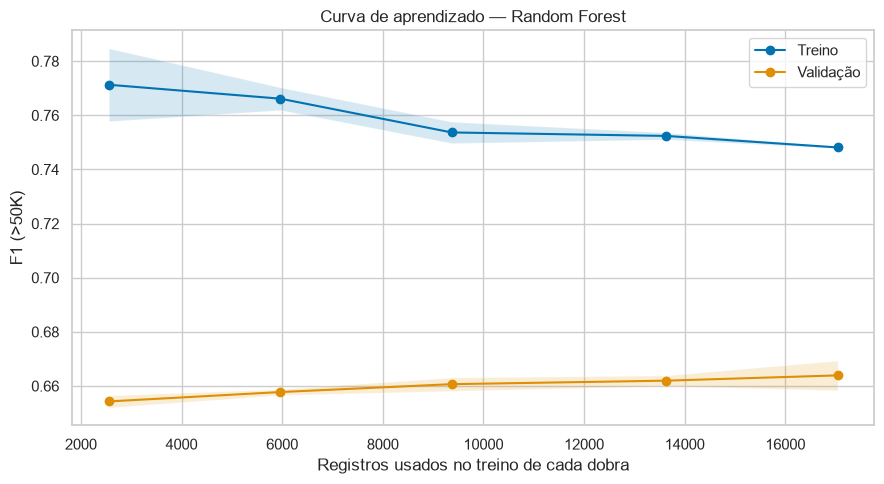

No maior tamanho, F1 treino = **0.7481** e validação = **0.6639**, com gap de **0.0842**. O ganho de validação entre os dois últimos tamanhos é **+0.0020**. O gap sugere variância residual: regularização pode ser mais útil do que apenas ampliar o treino. O trecho final mostra pouco ganho; não há evidência forte de que apenas mais dados resolvam o limite atual.

In [9]:
tamanhos, f1_tr, f1_va = learning_curve(clone(melhor),X_train,y_train,cv=DOBRAS,
    scoring=SCORING,train_sizes=[.15,.35,.55,.8,1.],shuffle=True,random_state=42,
    n_jobs=N_JOBS,error_score="raise")
fig,ax=plt.subplots(figsize=(9,5))
for valores,rotulo in [(f1_tr,"Treino"),(f1_va,"Validação")]:
    media,desvio=valores.mean(axis=1),valores.std(axis=1)
    ax.plot(tamanhos,media,"o-",label=rotulo)
    ax.fill_between(tamanhos,media-desvio,media+desvio,alpha=.16)
ax.set(xlabel="Registros usados no treino de cada dobra",ylabel="F1 (>50K)",
       title=f"Curva de aprendizado — {nome_base}")
ax.legend();plt.tight_layout();plt.show()
gap=f1_tr[-1].mean()-f1_va[-1].mean()
ganho=f1_va[-1].mean()-f1_va[-2].mean()
display(Markdown(f"No maior tamanho, F1 treino = **{f1_tr[-1].mean():.4f}** e "
 f"validação = **{f1_va[-1].mean():.4f}**, com gap de **{gap:.4f}**. "
 f"O ganho de validação entre os dois últimos tamanhos é **{ganho:+.4f}**. "
 + ("O gap sugere variância residual: regularização pode ser mais útil do que apenas ampliar o treino. " if gap>.07 else
    "O gap relativamente pequeno sugere menor variância, embora não exclua viés do modelo. ")
 + ("A curva ainda melhora no trecho final, apoiando testar mais dados comparáveis." if ganho>.003 else
    "O trecho final mostra pouco ganho; não há evidência forte de que apenas mais dados resolvam o limite atual.")))


## 5. Avaliação final no teste reservado
O modelo já foi refitado no treino completo pelo GridSearchCV. **A partir daqui não mudamos pipeline, parâmetros ou limiar.** Classe positiva = >50K. Falso positivo: prever >50K para renda <=50K. Falso negativo: não identificar uma pessoa com renda >50K. O custo social de cada erro depende do uso, que este experimento acadêmico não define.


,teste
Accuracy,0.7948
Precision (>50K),0.5502
Recall (>50K),0.8055
F1 (>50K),0.6538
ROC-AUC,0.8809


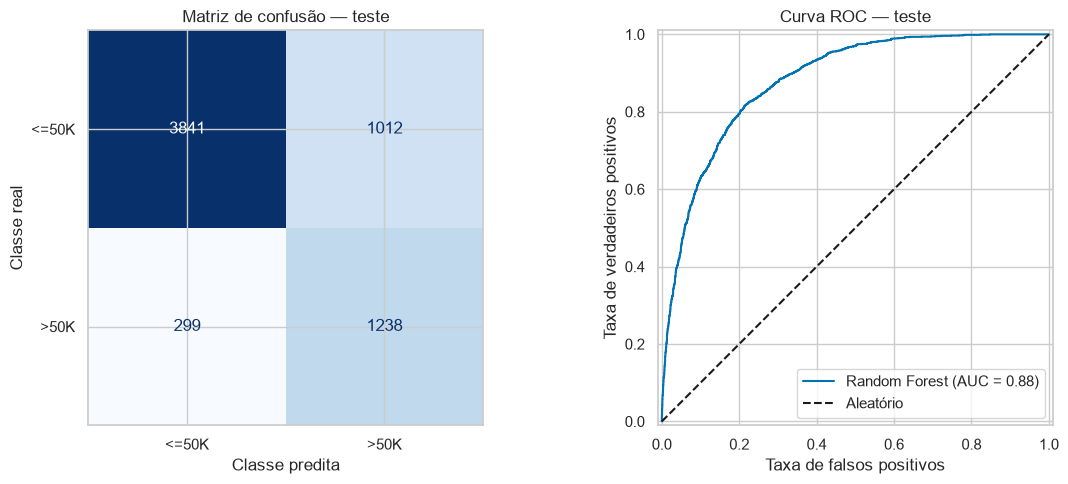

Foram **1238 verdadeiros positivos**, **3841 verdadeiros negativos**, **1012 falsos positivos** e **299 falsos negativos**. O modelo recupera **80.5%** da classe >50K; **45.0%** das previsões positivas estão erradas. F1 de teste (0.6538) difere da seleção CV (0.6627) em -0.0089. ROC-AUC mede ordenação ao variar o limiar e não comprova calibração das probabilidades.

IC bootstrap estratificado 95% do F1 (condicional ao modelo/split): [0.6394 0.6677]


In [10]:
pred = melhor.predict(X_test)
prob = melhor.predict_proba(X_test)[:,list(melhor.classes_).index(1)]
metricas = pd.Series({"Accuracy":accuracy_score(y_test,pred),
    "Precision (>50K)":precision_score(y_test,pred,zero_division=0),
    "Recall (>50K)":recall_score(y_test,pred,zero_division=0),
    "F1 (>50K)":f1_score(y_test,pred),"ROC-AUC":roc_auc_score(y_test,prob)})
display(metricas.to_frame("teste").round(4))
cm=confusion_matrix(y_test,pred,labels=[0,1]);tn,fp,fn,tp=cm.ravel()
fig,axs=plt.subplots(1,2,figsize=(12,5))
ConfusionMatrixDisplay(cm,display_labels=["<=50K",">50K"]).plot(ax=axs[0],cmap="Blues",colorbar=False)
axs[0].set(title="Matriz de confusão — teste",xlabel="Classe predita",ylabel="Classe real")
RocCurveDisplay.from_predictions(y_test,prob,name=nome_base,ax=axs[1])
axs[1].plot([0,1],[0,1],"k--",label="Aleatório")
axs[1].set(title="Curva ROC — teste",xlabel="Taxa de falsos positivos",ylabel="Taxa de verdadeiros positivos")
axs[1].legend();plt.tight_layout();plt.show()
display(Markdown(f"Foram **{tp} verdadeiros positivos**, **{tn} verdadeiros negativos**, "
 f"**{fp} falsos positivos** e **{fn} falsos negativos**. "
 f"O modelo recupera **{metricas['Recall (>50K)']:.1%}** da classe >50K; "
 f"**{1-metricas['Precision (>50K)']:.1%}** das previsões positivas estão erradas. "
 f"F1 de teste ({metricas['F1 (>50K)']:.4f}) difere da seleção CV "
 f"({busca_final.best_score_:.4f}) em {metricas['F1 (>50K)']-busca_final.best_score_:+.4f}. "
 "ROC-AUC mede ordenação ao variar o limiar e não comprova calibração das probabilidades."))
# Bootstrap estratificado apenas descritivo, sem nova seleção.
rng=np.random.default_rng(42); yt=y_test.to_numpy(); pr=np.asarray(pred)
idx0=np.flatnonzero(yt==0);idx1=np.flatnonzero(yt==1)
boot=[]
for _ in range(500):
    idx=np.r_[rng.choice(idx0,len(idx0)),rng.choice(idx1,len(idx1))]
    boot.append(f1_score(yt[idx],pr[idx]))
print("IC bootstrap estratificado 95% do F1 (condicional ao modelo/split):", np.quantile(boot,[.025,.975]).round(4))


**Leitura do compromisso precisão–recall:** a busca escolheu `class_weight="balanced"`, que aumenta o peso dos erros na classe minoritária. O recall de 80,5% acompanha uma precisão de 55,0% e 1.012 falsos positivos. Isso é coerente com a otimização de F1, mas não torna esse compromisso adequado a qualquer decisão concreta. A acurácia de 79,5% deve ser lida com essas duas taxas, e não isoladamente. O IC bootstrap é condicional ao modelo ajustado e não inclui a incerteza da seleção ou as dependências entre registros.

### 5.1 Auditoria por subgrupo
Diagnóstico pós-seleção, sem retreinar. Reportamos tamanho, número de positivos reais, precisão, recall, F1 e taxa de falsos positivos. Pequenos grupos podem produzir medidas instáveis; não interpretamos diferenças como discriminação causal nem ausência de diferença como prova de equidade [3].


In [11]:
aud=[]
for atributo in ["sex","race"]:
    for grupo, indices in X_test.groupby(atributo).groups.items():
        mascara=X_test.index.isin(indices); yy=y_test.to_numpy()[mascara]; pp=pred[mascara]
        neg=(yy==0).sum()
        aud.append({"atributo":atributo,"grupo":grupo,"n":len(yy),"positivos reais":int(yy.sum()),
          "precision":precision_score(yy,pp,zero_division=0),
          "recall":recall_score(yy,pp,zero_division=0) if yy.sum() else np.nan,
          "F1":f1_score(yy,pp,zero_division=0),
          "FPR":((yy==0)&(pp==1)).sum()/neg if neg else np.nan})
auditoria=pd.DataFrame(aud)
display(auditoria.round(4))


,atributo,grupo,n,positivos reais,precision,recall,F1,FPR
0,sex,Female,2132,238,0.5104,0.6176,0.5589,0.0744
1,sex,Male,4258,1299,0.5561,0.8399,0.6691,0.2944
2,race,Amer-Indian-Eskimo,61,7,0.4000,0.5714,0.4706,0.1111
3,race,Asian-Pac-Islander,189,56,0.6250,0.8036,0.7031,0.2030
4,race,Black,597,80,0.5392,0.6875,0.6044,0.0909
5,race,Other,44,2,0.3333,0.5000,0.4000,0.0476
6,race,White,5499,1392,0.5492,0.8139,0.6559,0.2264


**Leitura da auditoria.** Por sexo, a diferença é grande e tem direção clara:
- **Homens:** recall 0,84 e FPR 0,29. Quase três em cada dez homens com renda ≤50K são previstos como >50K.
- **Mulheres:** recall 0,62 e FPR 0,07. Cerca de 38% das mulheres com renda >50K não são identificadas, contra 16% dos homens.

Ou seja, o modelo erra a favor dos homens (mais falsos positivos) e contra as mulheres (mais falsos negativos). A precisão é parecida (0,51 contra 0,56). Isso é esperado quando as taxas-base diferem: 30,5% dos homens e 11,2% das mulheres do teste são >50K. Com taxas-base distintas, um classificador imperfeito não consegue igualar ao mesmo tempo a precisão e as taxas de erro entre grupos [9]. Os atributos de maior peso (casamento, `Husband`, sexo) ajudam a explicar o padrão, e o `class_weight="balanced"` amplia a tendência a prever >50K onde a taxa-base é maior.

Por raça, brancos e asiáticos têm recall de cerca de 0,80 e FPR de 0,20–0,23. Negros têm recall de 0,69 e FPR de 0,09, o mesmo padrão observado no recorte por sexo. `Amer-Indian-Eskimo` e `Other` têm só 7 e 2 positivos reais: uma única previsão muda o recall em 14 e 50 pontos percentuais, então esses valores não devem ser interpretados.

A ablação da seção 3.2 mostrou que retirar `sex` e `race` custa apenas −0,0006 de F1. Mesmo assim, essa remoção não igualaria os erros, porque `relationship` (`Husband`/`Wife`) e o estado civil continuam carregando a informação de sexo. Antes de qualquer uso seria preciso escolher, com quem será afetado, qual critério de equidade importa (por exemplo, recall igual entre grupos) e avaliar pós-processamento ou limiares por grupo. Não fizemos isso aqui, para não ajustar o modelo depois de ver o teste.

## 6. Interpretação e explicabilidade
### 6.1 Três maiores coeficientes do modelo linear
Usamos a logística ajustada no pipeline original, mesmo se ela não venceu. Numéricas estão padronizadas: um coeficiente equivale a aumentar um desvio-padrão mantendo as demais entradas. Indicadoras one-hot mudam de 0 para 1, mas com todas as categorias e regularização os coeficientes não têm uma categoria omitida única de referência. Sua magnitude não é diretamente comparável à de uma numérica. Colinearidade entre escolaridades e entre estado civil e relação familiar pode repartir sinal; associações são condicionais, sem interpretação causal.


In [12]:
linear=buscas["Logística L2"].best_estimator_
nomes_lin=linear.named_steps["preprocessor"].get_feature_names_out()
coef=linear.named_steps["model"].coef_[0]
top_coef=pd.DataFrame({"feature":nomes_lin,"coeficiente":coef,"magnitude":abs(coef)})
top_coef=top_coef.nlargest(3,"magnitude")
display(top_coef.round(4))
for r in top_coef.itertuples():
    display(Markdown(f"- **{r.feature}**: coeficiente {r.coeficiente:+.3f}; "
        f"associação com {'maiores' if r.coeficiente>0 else 'menores'} log-odds de >50K. "
        f"A razão de chances formal é exp(coef) = **{np.exp(r.coeficiente):.2f}**, "
        "sob as ressalvas de escala e codificação acima."))


,feature,coeficiente,magnitude
30,cat__marital.status_Married-civ-spouse,1.4162,1.4162
56,cat__relationship_Wife,1.2381,1.2381
50,cat__occupation_occupation,1.1417,1.1417


- **cat__marital.status_Married-civ-spouse**: coeficiente +1.416; associação com maiores log-odds de >50K. A razão de chances formal é exp(coef) = **4.12**, sob as ressalvas de escala e codificação acima.

- **cat__relationship_Wife**: coeficiente +1.238; associação com maiores log-odds de >50K. A razão de chances formal é exp(coef) = **3.45**, sob as ressalvas de escala e codificação acima.

- **cat__occupation_occupation**: coeficiente +1.142; associação com maiores log-odds de >50K. A razão de chances formal é exp(coef) = **3.13**, sob as ressalvas de escala e codificação acima.

**Leitura específica dos coeficientes obtidos:** `Married-civ-spouse` representa casamento civil e `Wife` o papel de esposa no domicílio. Os dois estão ligados à composição familiar e são correlacionados; seus coeficientes positivos não dizem que casar aumentaria a renda. O terceiro, `occupation_occupation`, é um marcador inválido de origem. Sua grande magnitude mostra que o modelo aprende um padrão de coleta/alteração do arquivo, além de associações socioeconômicas. O pequeno decréscimo de F1 ao limpá-lo não o transforma em informação ocupacional válida. Isso enfraquece a confiança na portabilidade e merece investigação antes de qualquer aplicação.

### 6.2 Três features mais importantes no ensemble
Apresentamos importância por redução média de impureza (MDI) da floresta original ajustada. O critério tende a privilegiar atributos com mais pontos de corte; com correlações, a importância pode ser dividida. Para evitar que uma categórica apareça fragmentada, também somamos as importâncias de suas indicadoras por atributo original. MDI e coeficientes não têm a mesma escala nem o mesmo significado.


,importância MDI — top 3 transformadas
cat__marital.status_Married-civ-spouse,0.136462
num__age,0.132963
num__education.num,0.097479


,importância MDI — top 3 originais
marital.status,0.213885
relationship,0.194491
age,0.132963


- **marital.status** concentra **21.4%** da redução de impureza total. Isso indica uso frequente/útil em divisões da floresta, sem demonstrar causalidade ou garantir que a remoção produziria queda proporcional de F1.

- **relationship** concentra **19.4%** da redução de impureza total. Isso indica uso frequente/útil em divisões da floresta, sem demonstrar causalidade ou garantir que a remoção produziria queda proporcional de F1.

- **age** concentra **13.3%** da redução de impureza total. Isso indica uso frequente/útil em divisões da floresta, sem demonstrar causalidade ou garantir que a remoção produziria queda proporcional de F1.

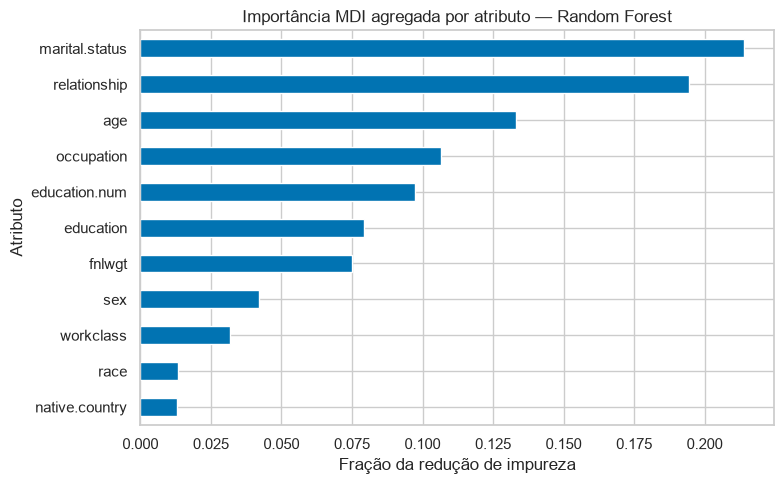

In [13]:
floresta=buscas["Random Forest"].best_estimator_
nomes_rf=floresta.named_steps["preprocessor"].get_feature_names_out()
mdi=pd.Series(floresta.named_steps["model"].feature_importances_,index=nomes_rf).sort_values(ascending=False)
display(mdi.head(3).rename("importância MDI — top 3 transformadas").to_frame())
def atributo_original(nome):
    if nome.startswith("num__"): return nome[5:]
    resto=nome[5:]
    return next(c for c in sorted(CAT,key=len,reverse=True) if resto.startswith(c+"_"))
mdi_original=mdi.groupby([atributo_original(n) for n in mdi.index]).sum().sort_values(ascending=False)
display(mdi_original.head(3).rename("importância MDI — top 3 originais").to_frame())
for nome,valor in mdi_original.head(3).items():
    display(Markdown(f"- **{nome}** concentra **{valor:.1%}** da redução de impureza total. "
        "Isso indica uso frequente/útil em divisões da floresta, sem demonstrar causalidade "
        "ou garantir que a remoção produziria queda proporcional de F1."))
ax=mdi_original.sort_values().plot.barh(figsize=(8,5))
ax.set(title="Importância MDI agregada por atributo — Random Forest",xlabel="Fração da redução de impureza",ylabel="Atributo")
plt.tight_layout();plt.show()


**Leitura específica do ensemble:** o estado civil é a maior importância agregada (21,4%), seguido pelo papel no domicílio (19,4%) e idade (13,3%). Estado civil e papel familiar podem compartilhar informação sobre estruturas domésticas e desigualdades históricas; idade permite divisões não lineares ao longo do ciclo de vida, mas sua MDI alta também pode ser favorecida pelo número de cortes possíveis. Na representação transformada, os três maiores são casamento civil, idade e escolaridade numérica. As duas listas respondem perguntas diferentes: importância de uma coluna codificada e importância do atributo inteiro. A comparação com a logística mostra sinal familiar em comum e salienta o artefato de ocupação no modelo linear.

### 6.3 SHAP global e três predições individuais do melhor modelo
Explicamos o **modelo final**, incluindo a transformação já ajustada. A amostra de referência de 40 pessoas e a amostra explicada de até 150 pessoas vêm **apenas do treino**, com sementes fixas; não selecionamos exemplos pelo erro ou pelo alvo. Para os três casos locais escolhemos as probabilidades mínima, mediana e máxima nessa amostra, oferecendo perfis de escores distintos.

Na floresta usamos TreeExplainer interventional em escala de probabilidade; na logística usamos LinearExplainer em log-odds. Sempre conferimos a aditividade contra a saída do estimador. O resumo global é a média de |SHAP| na amostra, não em toda a população. A hipótese interventional pode combinar categorias incompatíveis ou romper dependências: SHAP descreve como o modelo distribui a previsão em relação à referência, sem identificar efeitos causais [7].


Unidade: probabilidade de >50K | erro máximo de aditividade: 1.57969958225479e-08


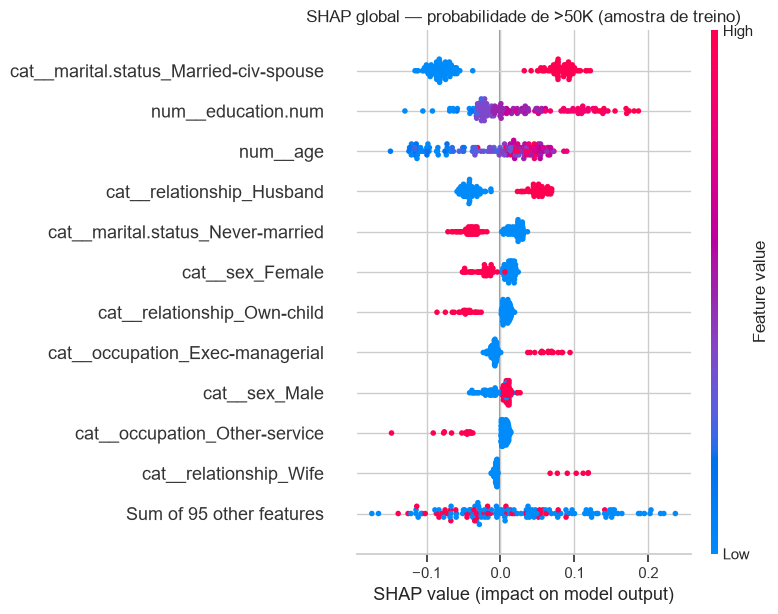

,média |SHAP|
cat__marital.status_Married-civ-spouse,0.080897
num__education.num,0.052151
num__age,0.051832
cat__relationship_Husband,0.045772
cat__marital.status_Never-married,0.028253
cat__sex_Female,0.016478
cat__relationship_Own-child,0.015043
cat__occupation_Exec-managerial,0.014699
cat__sex_Male,0.011696
cat__occupation_Other-service,0.011536


As três entradas com maior contribuição absoluta média são **cat__marital.status_Married-civ-spouse**, **num__education.num**, **num__age**. O sinal de cada ponto no gráfico indica deslocamento para maior ou menor saída em relação à referência; a cor representa o valor transformado, não a categoria textual original.

Caso 1 | índice original 199 | P(>50K)=0.0004 | real=0


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,native.country
199,17,?,181337,10th,6,Never-married,?,Own-child,Other,Female,United-States


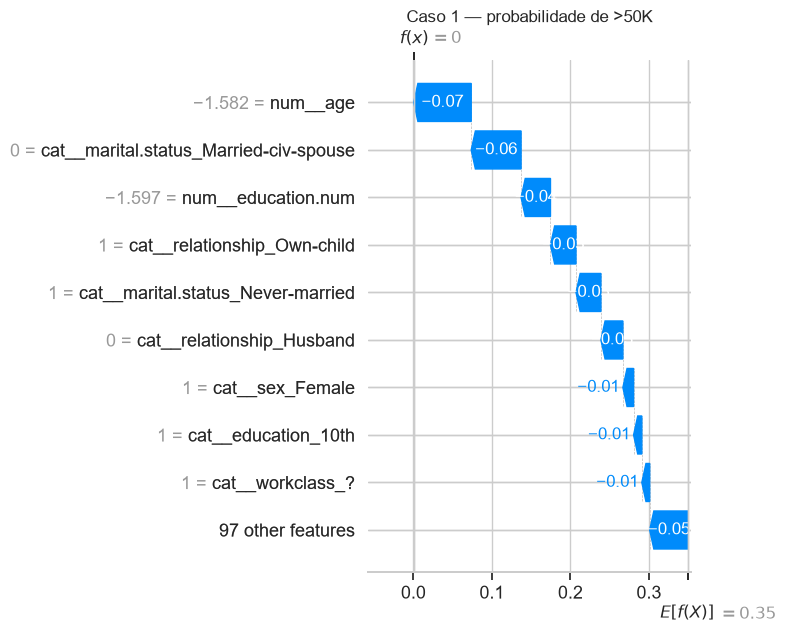

,contribuição SHAP
num__age,-0.073238
cat__marital.status_Married-civ-spouse,-0.063506
num__education.num,-0.037443


Base **0.3497** + soma SHAP **-0.3493** = saída **0.0004** (probabilidade de >50K). **num__age** reduz a saída em 0.0732; **cat__marital.status_Married-civ-spouse** reduz a saída em 0.0635; **num__education.num** reduz a saída em 0.0374. Essas contribuições explicam o escore do caso, sem prescrever mudanças reais na renda.

Caso 2 | índice original 17527 | P(>50K)=0.2944 | real=0


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,native.country
17527,39,Self-emp-not-inc,142573,Some-college,10,Never-married,Craft-repair,Not-in-family,White,Male,United-States


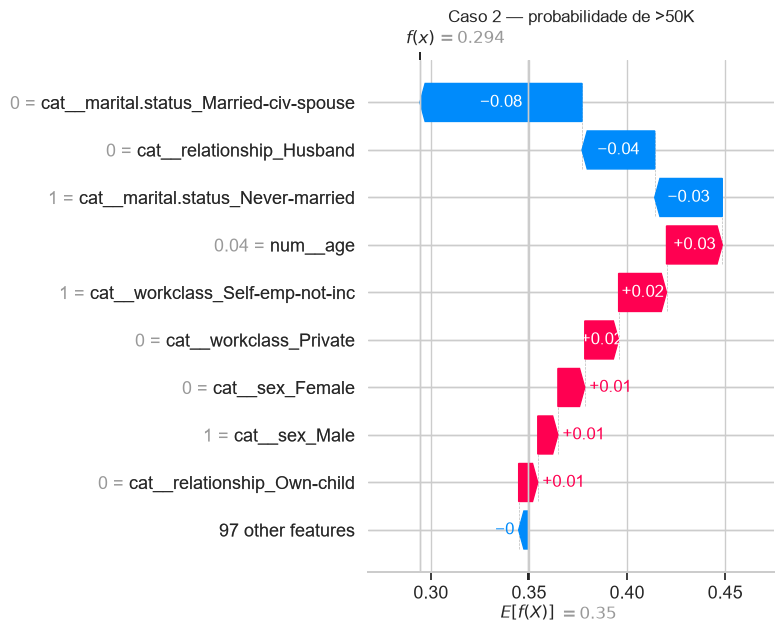

,contribuição SHAP
cat__marital.status_Married-civ-spouse,-0.082607
cat__relationship_Husband,-0.037050
cat__marital.status_Never-married,-0.034440


Base **0.3497** + soma SHAP **-0.0553** = saída **0.2944** (probabilidade de >50K). **cat__marital.status_Married-civ-spouse** reduz a saída em 0.0826; **cat__relationship_Husband** reduz a saída em 0.0370; **cat__marital.status_Never-married** reduz a saída em 0.0344. Essas contribuições explicam o escore do caso, sem prescrever mudanças reais na renda.

Caso 3 | índice original 25035 | P(>50K)=0.9718 | real=1


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,native.country
25035,50,Private,134766,Bachelors,13,Married-civ-spouse,occupation,Husband,White,Male,United-States


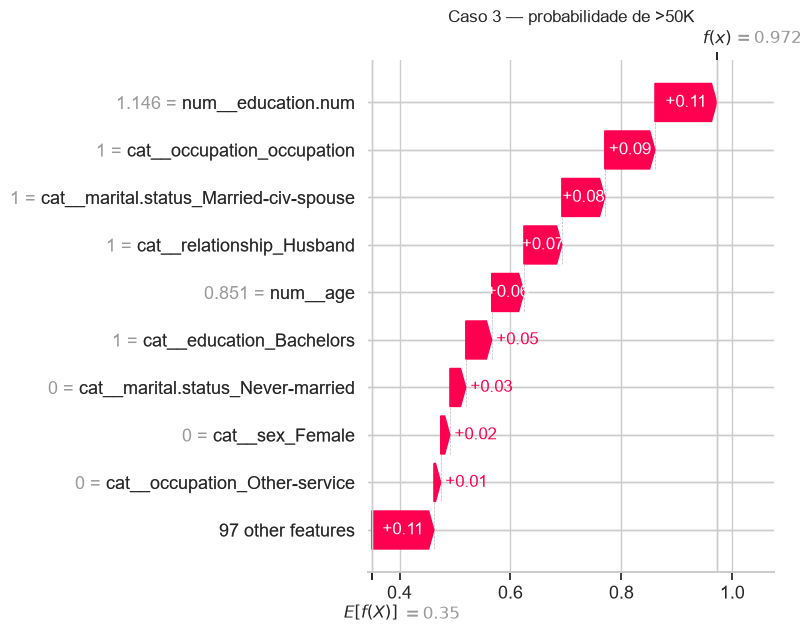

,contribuição SHAP
num__education.num,0.111391
cat__occupation_occupation,0.090439
cat__marital.status_Married-civ-spouse,0.077394


Base **0.3497** + soma SHAP **+0.6221** = saída **0.9718** (probabilidade de >50K). **num__education.num** eleva a saída em 0.1114; **cat__occupation_occupation** eleva a saída em 0.0904; **cat__marital.status_Married-civ-spouse** eleva a saída em 0.0774. Essas contribuições explicam o escore do caso, sem prescrever mudanças reais na renda.

In [14]:
background=X_train.sample(n=40,random_state=42)
explicar=X_train.sample(n=min(150,len(X_train)),random_state=43)
# Float32 reproduz a precisão de entrada das árvores sklearn e evita divergências
# numéricas em comparações com limiares. A fatia inclui a limpeza selecionada.
transformar=melhor[:-1]
Zref=np.asarray(transformar.transform(background),dtype=np.float32)
Z=np.asarray(transformar.transform(explicar),dtype=np.float32)
nomes=melhor.named_steps["preprocessor"].get_feature_names_out().tolist()
estimador=melhor.named_steps["model"]
if isinstance(estimador,RandomForestClassifier):
    explainer=shap.TreeExplainer(estimador,data=Zref,feature_perturbation="interventional",model_output="probability")
    bruta=explainer(Z,check_additivity=False)
    if bruta.values.ndim==3:
        valores=bruta.values[:,:,1]; bases=np.asarray(bruta.base_values)[:,1]
    else:
        valores=bruta.values; bases=np.asarray(bruta.base_values)
    saida=melhor.predict_proba(explicar)[:,1]
    unidade="probabilidade de >50K"
else:
    explainer=shap.LinearExplainer(estimador,Zref)
    bruta=explainer(Z)
    valores=bruta.values; bases=np.broadcast_to(bruta.base_values,(len(Z),))
    saida=melhor.decision_function(explicar)
    unidade="log-odds de >50K"
explanacao=shap.Explanation(values=valores,base_values=bases,data=Z,feature_names=nomes)
erro_aditivo=np.max(abs(bases+valores.sum(axis=1)-saida))
assert erro_aditivo<1e-4, erro_aditivo
print("Unidade:",unidade,"| erro máximo de aditividade:",erro_aditivo)
shap.plots.beeswarm(explanacao,max_display=12,show=False)
plt.title(f"SHAP global — {unidade} (amostra de treino)");plt.tight_layout();plt.show()
import_global=pd.Series(np.abs(valores).mean(axis=0),index=nomes).sort_values(ascending=False)
display(import_global.head(10).rename("média |SHAP|").to_frame())
display(Markdown("As três entradas com maior contribuição absoluta média são **"+
    "**, **".join(import_global.head(3).index)+"**. O sinal de cada ponto no gráfico "
    "indica deslocamento para maior ou menor saída em relação à referência; "
    "a cor representa o valor transformado, não a categoria textual original."))
p_amostra=melhor.predict_proba(explicar)[:,1]
ordem=np.argsort(p_amostra)
selecionados=[ordem[0],ordem[len(ordem)//2],ordem[-1]]
for numero,i in enumerate(selecionados,1):
    print(f"Caso {numero} | índice original {explicar.index[i]} | P(>50K)={p_amostra[i]:.4f} | real={y_train.loc[explicar.index[i]]}")
    display(explicar.iloc[[i]])
    shap.plots.waterfall(explanacao[i],max_display=10,show=False)
    plt.title(f"Caso {numero} — {unidade}");plt.tight_layout();plt.show()
    local=pd.Series(valores[i],index=nomes)
    top=local.loc[local.abs().nlargest(3).index]
    display(top.rename("contribuição SHAP").to_frame())
    display(Markdown(f"Base **{bases[i]:.4f}** + soma SHAP **{valores[i].sum():+.4f}** "
       f"= saída **{saida[i]:.4f}** ({unidade}). "
       + "; ".join(f"**{n}** {'eleva' if v>0 else 'reduz'} a saída em {abs(v):.4f}" for n,v in top.items())
       + ". Essas contribuições explicam o escore do caso, sem prescrever mudanças reais na renda."))


**Leitura do SHAP global.** O estado civil `Married-civ-spouse` é a entrada com maior contribuição média (≈0,08 de probabilidade): ser casado desloca a previsão para cima em cerca de 0,07–0,10 e não ser casado a desloca para baixo em magnitude semelhante. `education.num` vem em seguida, com efeito monotônico: escolaridades altas (vermelho) chegam a +0,19 e baixas (azul) reduzem a previsão. Em `age`, idades baixas produzem as maiores reduções (até ≈−0,12), enquanto idades médias e altas têm efeito positivo mais moderado e parecido entre si, um padrão não linear que a floresta captura e a logística não. O sinal familiar aparece repartido entre `marital.status`, `relationship_Husband`/`Wife` e `sex`, atributos fortemente correlacionados. Os três primeiros coincidem com o top 3 da MDI transformada (seção 6.2), o que reforça a conclusão por dois métodos com hipóteses diferentes. Entre as ocupações válidas, apenas `Exec-managerial` (positiva) e `Other-service` (negativa) aparecem no top 11.

**Leitura dos três casos.**
- **Caso 1 (P=0,0004, real ≤50K):** jovem de 17 anos, 10ª série, solteira e filha no domicílio. Idade, ausência de casamento e baixa escolaridade empurram na mesma direção. Boa parte do restante vem de outras indicadoras familiares (`Own-child`, `Never-married` e não ser `Husband`, ≈−0,09 juntas), além de pequenos efeitos de sexo, escolaridade categórica e `workclass` `?`. É um perfil típico de dependente, e o modelo acerta com folga.
- **Caso 2 (P=0,294, real ≤50K):** homem de 39 anos, autônomo, nunca casado e sem família no domicílio. As três maiores contribuições negativas são todas familiares (não casado, não `Husband`, `Never-married`, somando ≈−0,15). Idade, `Self-emp-not-inc` e sexo masculino compensam parte disso (≈+0,08). A previsão fica abaixo do limiar 0,5 sobretudo pela estrutura familiar, e não por escolaridade ou ocupação.
- **Caso 3 (P=0,972, real >50K):** homem de 50 anos, bacharel e casado. Escolaridade (+0,11), casamento (+0,08), `Husband` e idade explicam a maior parte da previsão. Porém a **segunda maior contribuição (+0,09) é `occupation_occupation`**, o valor inválido. O modelo usa o próprio marcador de erro como evidência de renda alta, coerente com o diagnóstico da seção 3.1: no treino, 53,9% das linhas com esse sentinela são >50K. A previsão está certa, mas parte da justificativa interna do modelo vem de um artefato do arquivo, o que ilustra concretamente o risco discutido na seção 3.1.

Os três casos foram escolhidos por probabilidade (mínima, mediana e máxima) e acabaram todos classificados corretamente. Explicar também um falso positivo e um falso negativo mostraria onde o modelo erra; fica como extensão natural.

## 7. Discussão crítica fundamentada
As limitações abaixo acrescentam aspectos aos já discutidos na APS1 (recorte histórico, geografia, inflação, atributos ausentes e causalidade). Os itens sobre o modelo valem para a família selecionada, seja logística ou floresta.

### Duas limitações adicionais do modelo
1. **Escores não calibrados e limiar sem custo de decisão definido.** Maximizar F1 não garante que uma previsão de 0,8 corresponda a 80% de frequência observada, nem que 0,5 minimize o custo dos erros. O número exibido como probabilidade é uma saída do estimador, não uma frequência validada. Uma etapa posterior deve medir curva de calibração/Brier score e ajustar calibração e limiar em validação separada, com custos e finalidade explicitados; isso não foi feito neste experimento. Niculescu-Mizil e Caruana [5] mostram que qualidade discriminativa e qualidade das probabilidades são aspectos diferentes.
2. **Ausência de mecanismo de abstenção para entradas fora do suporte.** O pipeline produz uma decisão mesmo para uma categoria desconhecida (one-hot zerado) ou um perfil muito distante dos registros de ajuste. Não existe detector de distribuição, regra de rejeição ou garantia individual de confiança. O F1 médio no teste não mede essa condição. A documentação do modelo deve declarar domínios aceitos e limites, e prever revisão humana para casos fora do suporte [3, 6].

### Duas limitações adicionais dos dados
1. **Seleção condicionada da população de origem.** A documentação UCI informa filtros como idade >16, renda bruta ajustada >100, peso amostral >1 e horas trabalhadas >0 [2]. Portanto, o universo de pessoas elegíveis já exclui segmentos antes da amostragem; bom desempenho no Adult não sustenta generalização a desempregados, menores ou população irrestrita. A versão reduzida não permite reconstruir todos os filtros, e a seleção merece registro no datasheet [4].
2. **Proveniência incompleta das alterações na cópia Kaggle.** A versão utilizada contém o valor inválido `occupation` em diversas linhas e não acompanha um histórico de quais registros foram modificados. Converter o marcador em NaN evita aprender uma ocupação inexistente, mas não recupera a informação original nem demonstra ausência de outras alterações. É uma limitação de rastreabilidade, além da simples existência de ausentes. O snapshot e o hash tornam este experimento reprodutível, mas validar a equivalência com a fonte original exigiria chaves ou um registro de transformações [4].

### Duas ações para operacionalização e manutenção
1. **Empacotar um contrato de entrada e uma versão auditável.** Antes de qualquer uso, definir finalidade e usos proibidos, validar domínio e categorias, testar o pipeline completo, registrar hash dos dados, versões de dependências, parâmetros, limiar e responsável. Publicar model card com desempenho por subgrupo e condições de revisão humana [3]. O modelo aqui tem finalidade acadêmica; um sistema real precisaria validar dados contemporâneos da população de interesse e autorização apropriada.
2. **Monitorar e revisar com rótulos posteriores.** Acompanhar mensalmente taxas de ausentes/categorias novas, distribuição de escores, F1, precisão, recall, calibração e métricas por subgrupo quando os rótulos chegarem. Definir antes da implantação limites de alerta por janela e tamanho amostral; investigar mudança de coleta antes de retreinar. Comparar candidato com versão vigente em conjunto temporal separado, registrar aprovação e manter rollback. Isso aborda dependências e dívida técnica descritas por Sculley et al. [6]; retreino automático sem diagnóstico pode perpetuar defeitos de dados.

**Limites da conclusão:** a validação de três dobras e a grade restrita atendem à comparação acadêmica, mas não esgotam hiperparâmetros nem medem variação temporal. A seleção é feita exclusivamente no treino; o teste sustenta apenas o desempenho na partição e no universo observados.


## 8. Síntese dos resultados e conferência da rubrica


In [15]:
display(Markdown(f"O procedimento final usa **{nome_base}**, pipeline "
 f"**{'com limpeza de sentinelas' if usou_limpeza else 'original da APS1'}**, "
 f"F1 CV **{busca_final.best_score_:.4f}** e F1 de teste **{metricas['F1 (>50K)']:.4f}**. "
 f"A alteração teve ΔF1 CV de **{delta:+.4f}**. "
 f"No teste, Accuracy = **{metricas['Accuracy']:.4f}**, Precision = **{metricas['Precision (>50K)']:.4f}**, "
 f"Recall = **{metricas['Recall (>50K)']:.4f}** e ROC-AUC = **{metricas['ROC-AUC']:.4f}**. "
 "O notebook preserva resultados negativos e não troca o modelo com base no teste."))
display(pd.DataFrame([
 ["3 modelos e métrica comum","2"], ["Ajuste linear e ensemble","2.1"],
 ["Mudança, nova busca e comparação","3"], ["Curvas de aprendizado","4"],
 ["Accuracy, Precision, Recall, F1, confusão, ROC e AUC","5"],
 ["3 coeficientes e 3 importâncias","6.1–6.2"],
 ["SHAP global e 3 predições locais","6.3"],
 ["2 limitações do modelo + 2 dos dados + 2 ações","7"],
 ["Referências, identificação e data","Capa e 9"]],columns=["Requisito","Seção"]))


O procedimento final usa **Random Forest**, pipeline **original da APS1**, F1 CV **0.6627** e F1 de teste **0.6538**. A alteração teve ΔF1 CV de **-0.0016**. No teste, Accuracy = **0.7948**, Precision = **0.5502**, Recall = **0.8055** e ROC-AUC = **0.8809**. O notebook preserva resultados negativos e não troca o modelo com base no teste.

,Requisito,Seção
0,3 modelos e métrica comum,2
1,Ajuste linear e ensemble,2.1
2,"Mudança, nova busca e comparação",3
3,Curvas de aprendizado,4
4,"Accuracy, Precision, Recall, F1, confusão, ROC e AUC",5
5,3 coeficientes e 3 importâncias,6.1–6.2
6,SHAP global e 3 predições locais,6.3
7,2 limitações do modelo + 2 dos dados + 2 ações,7
8,"Referências, identificação e data",Capa e 9


## 9. Referências
Acesso em 16/10/2026. As fontes abaixo fundamentam métodos e discussão; as inferências específicas do experimento estão identificadas no texto.

1. KAGGLE. **Adult Income Census**, por anaghakp. https://www.kaggle.com/datasets/anaghakp/adult-income-census. Snapshot do arquivo `adult income1.csv` incorporado neste notebook. APS1: https://colab.research.google.com/drive/1FVFVb_z23nnDKqQuPjWYlWyEqv4rWRCc. Rubrica: https://colab.research.google.com/drive/1sW6GFmk9OxxCs072sQWSxA7EyugpUBN2.
2. BECKER, B.; KOHAVI, R. **Adult [Dataset]**. UCI Machine Learning Repository, 1996. https://doi.org/10.24432/C5XW20. Documentação: https://archive.ics.uci.edu/dataset/2/adult.
3. MITCHELL, M. et al. **Model Cards for Model Reporting**. FAT*, 2019. https://arxiv.org/abs/1810.03993.
4. GEBRU, T. et al. **Datasheets for Datasets**. Communications of the ACM, 2021. https://arxiv.org/abs/1803.09010.
5. NICULESCU-MIZIL, A.; CARUANA, R. **Predicting Good Probabilities with Supervised Learning**. ICML, 2005. https://www.cs.cornell.edu/~alexn/papers/calibration.icml05.crc.rev3.pdf.
6. SCULLEY, D. et al. **Hidden Technical Debt in Machine Learning Systems**. NeurIPS, 2015. https://research.google/pubs/hidden-technical-debt-in-machine-learning-systems/.
7. LUNDBERG, S. M.; LEE, S.-I. **A Unified Approach to Interpreting Model Predictions**. NeurIPS, 2017. https://arxiv.org/abs/1705.07874. Documentação TreeExplainer: https://shap.readthedocs.io/en/stable/generated/shap.TreeExplainer.html; LinearExplainer: https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html.
8. SCIKIT-LEARN. **Documentação oficial**: Pipeline, GridSearchCV, learning_curve, LogisticRegression e RandomForestClassifier. https://scikit-learn.org/stable/. Curvas: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html.
9. CHOULDECHOVA, A. **Fair Prediction with Disparate Impact: A Study of Bias in Recidivism Prediction Instruments**. Big Data, v. 5, n. 2, 2017. https://arxiv.org/abs/1610.07524.

**Entrega e documentação aberta:** além deste `.ipynb`, o projeto está publicado no GitHub Pages, com a APS1 e a APS2 renderizadas com todas as saídas: https://viviraia.github.io/ml-adult-income/. O código-fonte do site e os notebooks ficam no repositório https://github.com/viviraia/ml-adult-income.
